
# Photograph-Based Estimation of Projected Plant Area and Its Distribution Along Branching Submerged Aquatic Vegetation

**OEAS 805 — Advanced Environmental Data Analysis**  
**Final Project **

### Research Question
How does projected plant area vary with cumulative distance along the branching architecture of submerged aquatic vegetation?

### Project Overview
This notebook develops a photograph-based workflow for estimating projected plant area and its distribution along plant axes. Using GoPro photographs of Myriophyllum collected from Susquehanna Flats, the analysis combines unsupervised image classification, pixel-to-centimeter conversion, and stem tracing to quantify projected area within 1-cm intervals along the plant axes.

The workflow is demonstrated using a single branch of shoot IDX 3 and extended to reconstruct the whole-shoot projected-area distribution. Future analyses will include the remaining sampled shoots to estimate a mean distribution and characterize between-shoot variability.


In [1]:

# 4. Import Libraries

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from sklearn.cluster import KMeans
from matplotlib.path import Path as MplPath

# Display figures within the notebook
%matplotlib inline

print("Libraries imported successfully.")


Libraries imported successfully.



## 2. Data Description and Access

This project uses three datasets collected and prepared as part of research on submerged aquatic vegetation (SAV) from Susquehanna Flats, Maryland. The present analysis focuses on branching *Myriophyllum* samples.

### Datasets

1. **GoPro RGB photographs:** Photographs of individual plant shoots and branches used to estimate two-dimensional projected plant area and its distribution along plant axes. Each photograph includes blue reference disks used for spatial calibration.

2. **GoPro image metadata:** A table containing previously determined blue-channel thresholds, mean pixel sizes (cm/pixel), and mean pixel areas (cm²/pixel) for individual photographs. These measurements provide the conversion factors needed to express plant dimensions and projected area in physical units.

3. **Plant morphology measurements and image references:** A table containing measurements of sampled plants and identifiers linking each shoot (IDX) to its reference photograph and individual branch photographs. These references allow measurements from separate images to be combined into a whole-shoot distribution.

### Previously Completed Image Calibration

Each GoPro photograph includes 3D-printed blue reference disks of known physical area. During a previous calibration procedure, a blue-channel brightness threshold was used to identify the disks and count their pixels.

The known physical area of each disk was divided by its pixel count to estimate the physical area represented by one pixel. These estimates were averaged to obtain an image-specific mean pixel-area conversion factor.

The resulting calibration values are stored in `GoPro_Metadata_Susquehanna_milfoil.xlsx` and are used in this notebook to convert classified plant pixels into projected area (cm²). The calibration procedure itself is not repeated here.

**Note:** The blue-channel threshold used to identify calibration disks is distinct from the image-classification methods used to identify plant tissue.

### Scope of This Notebook

The workflow is demonstrated using Branch 2 of shoot IDX 3, which has a single main axis without secondary branches. The reviewer can perform image classification and stem tracing on this branch to reproduce its projected-area distribution.

Previously processed measurements from all five branches of IDX 3 are then combined to reconstruct the whole-shoot distribution. The remaining eight sampled shoots will be analyzed in future work to estimate a mean projected-area profile and characterize between-shoot variability.


In [ ]:
# Define file paths
# Note to Lu: Replace the three paths below with the locations
# of the corresponding files and image folder on your computer.

morphology_path = Path(r"PASTE FULL PATH TO Morphmeasures_Susquehanna_milfoil.xlsx HERE")

metadata_path = Path(r"PASTE FULL PATH TO GoPro_Metadata_Susquehanna_milfoil.xlsx HERE")

image_folder = Path(r"PASTE FULL PATH TO GoProImages_Susquehanna_Milfoil FOLDER HERE")


# Load morphology measurements
morphmeasures = pd.read_excel(morphology_path)

# Load image calibration metadata
gopro_metadata = pd.read_excel(
    metadata_path,
    sheet_name="MorphoMassMeasurements"
)

# Check that data loaded correctly
print("Number of shoots:", morphmeasures["IDX"].nunique())
print("Shoot IDs:", sorted(morphmeasures["IDX"].dropna().unique()))
print("Number of metadata records:", len(gopro_metadata))


Number of shoots: 9
Shoot IDs: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Number of metadata records: 26



## 3. Methodological Development: From Color Thresholding to Unsupervised Classification

### The Challenge of Measuring Complex Plant Architecture

Estimating projected plant area is relatively straightforward when leaves have simple geometries. However, branching submerged aquatic vegetation such as *Myriophyllum* has finely divided leaves and complex stem arrangements that make conventional geometric measurements difficult.

Digital image analysis offers an alternative by identifying plant tissue at the pixel level. Once plant pixels are identified, their total projected area can be estimated and their positions along the plant's branching structure can be determined.

### Initial Approach: Color Thresholding

The initial approach explored using RGB color information to distinguish plant tissue from the photographic background. In particular, thresholds applied to individual color channels were investigated as a way to produce binary plant masks.

Although thresholding is computationally simple, its effectiveness depends on the spectral and brightness differences between plant tissue and the background. Variation in illumination, shadows, and plant coloration can complicate the selection of a single threshold that performs consistently across photographs.

### Revised Approach: Unsupervised K-Means Classification

To reduce dependence on manually selected color thresholds, the workflow was revised to use K-means clustering.

K-means is an unsupervised classification algorithm that groups pixels according to similarities in their RGB values. In this analysis, the number of clusters is set to two (k = 2), with the goal of separating plant tissue from the background.

Because K-means does not assign meaningful labels to its clusters, the cluster corresponding to plant tissue must be identified after classification.

The resulting binary plant mask is used to calculate total projected plant area and, together with traced plant axes, estimate how that area is distributed along the plant.

### Analytical Objective

The purpose of classification is not simply to identify plant pixels, but to use those pixels to investigate the relationship between projected plant area and cumulative distance along the branching architecture of a shoot.

The following sections demonstrate this workflow using Branch 2 of shoot IDX 3 before reconstructing the projected-area distribution of the complete shoot.


In [3]:

# Select shoot and branch
selected_idx = 3
selected_branch = 2

# Find the corresponding morphology records
branch_info = morphmeasures.loc[
    (morphmeasures["IDX"] == selected_idx) &
    (morphmeasures["BRANCHNUM"] == selected_branch)
]

if branch_info.empty:
    raise ValueError(
        f"Branch {selected_branch} was not found for IDX {selected_idx}."
    )

# Get the branch photograph filename
branch_filename = str(branch_info["BRANCH"].dropna().iloc[0]).strip()

if not branch_filename.lower().endswith((".jpg", ".jpeg", ".png")):
    branch_filename += ".JPG"

# Construct image path
image_path = image_folder / branch_filename

print("Selected shoot:", selected_idx)
print("Selected branch:", selected_branch)
print("Photograph:", branch_filename)
print("Image found:", image_path.is_file())


Selected shoot: 3
Selected branch: 2
Photograph: GOPR1167.JPG
Image found: True


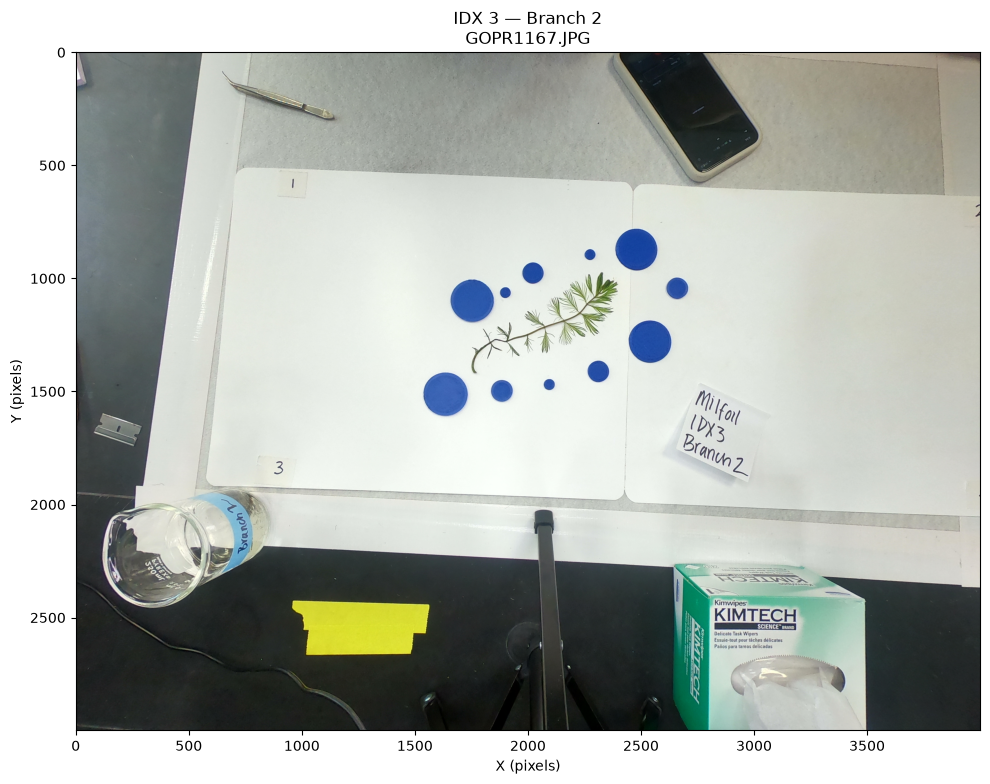

Image shape: (3000, 4000, 3)


In [4]:

# Load Branch 2 photograph
branch_image = mpimg.imread(image_path)

# Display photograph
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(branch_image)
ax.set_title(
    f"IDX {selected_idx} — Branch {selected_branch}\n"
    f"{branch_filename}"
)
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")

plt.tight_layout()
plt.show()

# Check image dimensions
print("Image shape:", branch_image.shape)


## 4. Image Preprocessing: Interactive Polygon Cropping

Before performing unsupervised classification, the photograph is cropped to isolate the plant from unnecessary background features, including the blue calibration circles.

A polygon is drawn around the plant using `matplotlib.pyplot.ginput()`. This allows the user to define a region of interest (ROI) that follows the plant's irregular shape rather than relying on a rectangular crop.

**The ROI should contain only plant tissue and its immediate background.** The blue calibration circles should be excluded because they are not part of the plant and could influence the subsequent classification. Pixel-to-centimeter calibration values have already been calculated and are available in the GoPro metadata spreadsheet.

Pixels outside the selected polygon are excluded from the subsequent K-means classification.

### Instructions for Lu

1. Run the following cell to display the photograph in an interactive window.
2. Left-click to place points around the plant, enclosing **all visible plant tissue while excluding the blue calibration circles**.
3. Press **Enter** when you have finished selecting the polygon vertices.
4. Inspect the resulting cropped photograph to ensure that the entire plant is included and the blue circles are excluded.
5. If necessary, rerun the cell to redraw the polygon.

**Note:** Interactive point selection requires a Matplotlib backend that supports mouse input. This notebook uses `%matplotlib tk` to open the interactive figure in a separate window.

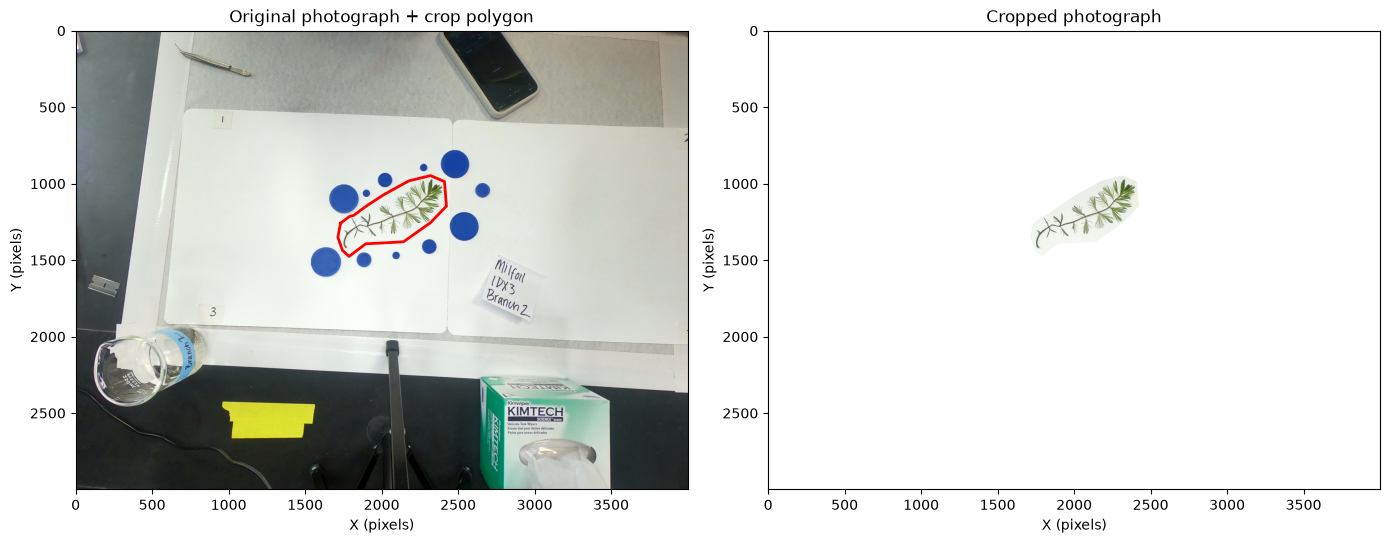

Pixels inside crop: 202039


In [5]:

%matplotlib tk

# STEP 1: Display photograph for cropping
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(branch_image)

ax.set_title(
    f"IDX {selected_idx} — Branch {selected_branch}\n"
    "Click around the ENTIRE plant to draw a polygon\n"
    "Press ENTER when finished"
)

# STEP 2: Record polygon vertices
crop_points = np.array(plt.ginput(n=-1, timeout=0))
plt.close(fig)

if len(crop_points) < 3:
    raise ValueError("At least 3 points are needed to draw a polygon.")

# STEP 3: Convert polygon into a binary mask
height, width = branch_image.shape[:2]

yy, xx = np.mgrid[:height, :width]
pixel_coordinates = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

crop_polygon = MplPath(crop_points)

crop_mask = crop_polygon.contains_points(
    pixel_coordinates
).reshape(height, width)

# STEP 4: Apply mask to photograph
cropped_rgb = branch_image.copy()
cropped_rgb[~crop_mask] = 255

# STEP 5: Display cropping result
%matplotlib inline

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(branch_image)
axes[0].plot(
    np.r_[crop_points[:, 0], crop_points[0, 0]],
    np.r_[crop_points[:, 1], crop_points[0, 1]],
    "r-",
    linewidth=2
)
axes[0].set_title("Original photograph + crop polygon")

axes[1].imshow(cropped_rgb)
axes[1].set_title("Cropped photograph")

for ax in axes:
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")

plt.tight_layout()
plt.show()

print("Pixels inside crop:", np.count_nonzero(crop_mask))


### Instructions for Lu

1. Run the following cell to perform an unsupervised K-means classification.
2. Once K-means classification is output, you have to manually respond to the question Which cluster represents plant tissue? (0 or 1), then press enter
3. Final outputs will be the classification and a binary mask where all the plant pixels were multiplied by mean pixel area to determine total projected plant area

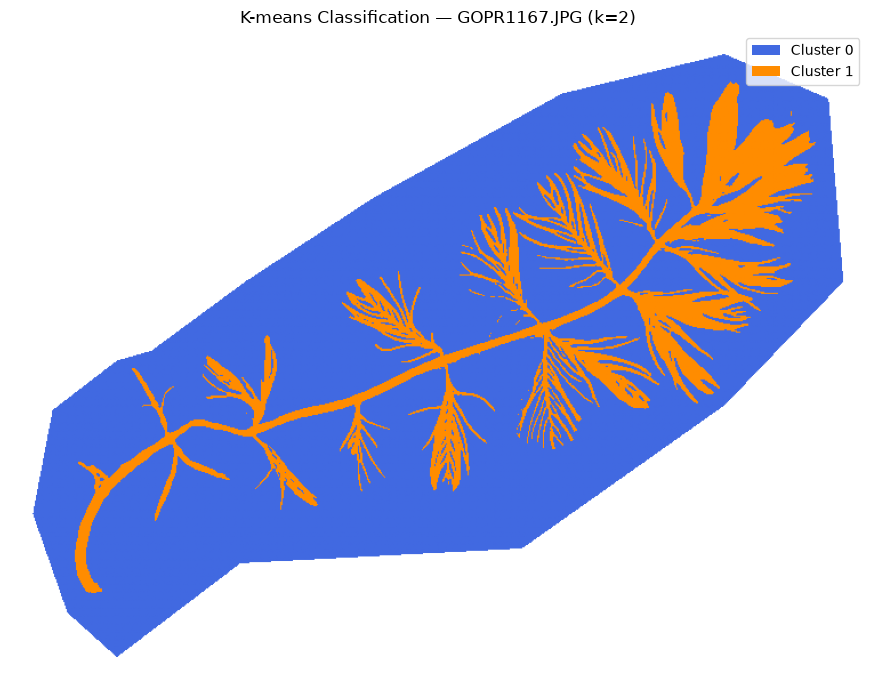


Photograph: GOPR1167.JPG
Plant cluster: 1
Plant pixels: 37,568
Pixel area: 0.000497 cm²/pixel
Total projected plant area: 18.67 cm²


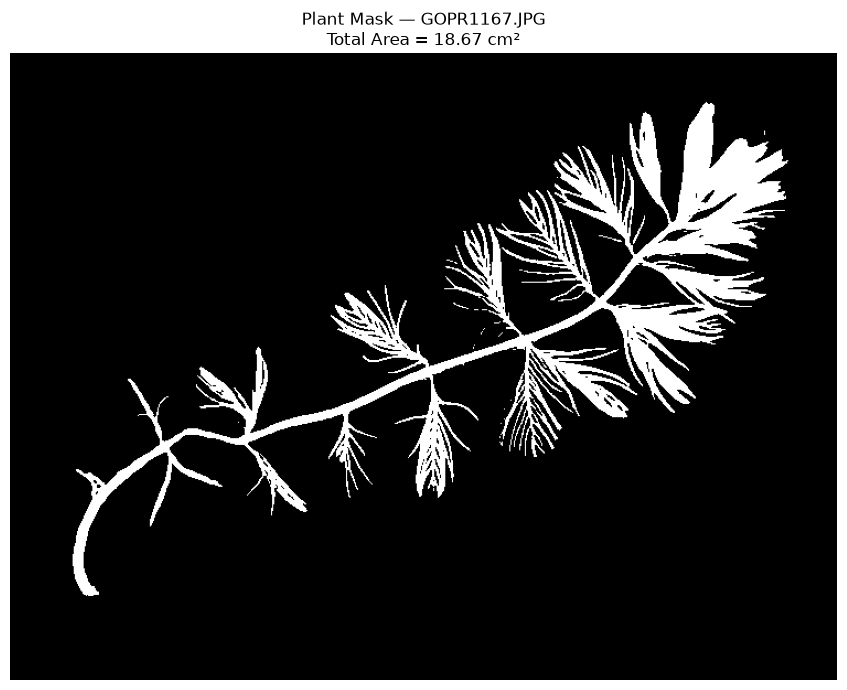

In [9]:

# ==================================================
# K-MEANS CLASSIFICATION AND TOTAL PLANT AREA
# ==================================================

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --------------------------------------------------
# STEP 1: Prepare image pixels
# --------------------------------------------------

image = np.asarray(cropped_rgb)

# Exclude pixels outside the crop polygon
valid_mask = crop_mask

valid_pixels = image[valid_mask].reshape(-1, 3)

# Determine display extent
xmin, ymin = crop_points.min(axis=0)
xmax, ymax = crop_points.max(axis=0)


# --------------------------------------------------
# STEP 2: Run K-means classification
# --------------------------------------------------

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(valid_pixels)


# --------------------------------------------------
# STEP 3: Reconstruct classification image
# --------------------------------------------------

classified = np.full(
    image.shape[:2],
    np.nan
)

classified[valid_mask] = labels


# --------------------------------------------------
# STEP 4: Visualize both clusters
# --------------------------------------------------

cluster_cmap = ListedColormap(["royalblue", "darkorange"])
cluster_cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(10, 7))

ax.imshow(
    classified,
    cmap=cluster_cmap,
    vmin=-0.5,
    vmax=1.5
)

ax.set_title(
    f"K-means Classification — {branch_filename} (k=2)"
)

ax.set_xlim(xmin - 20, xmax + 20)
ax.set_ylim(ymax + 20, ymin - 20)

ax.axis("off")

ax.legend(
    handles=[
        Patch(facecolor="royalblue", label="Cluster 0"),
        Patch(facecolor="darkorange", label="Cluster 1")
    ],
    loc="upper right"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# STEP 5: Ask user to identify plant cluster
# --------------------------------------------------

while True:
    plant_cluster = input(
        "Which cluster represents plant tissue? (0 or 1): "
    ).strip()

    if plant_cluster in ["0", "1"]:
        plant_cluster = int(plant_cluster)
        break

    print("Please enter 0 or 1.")


# --------------------------------------------------
# STEP 6: Create binary plant mask
# --------------------------------------------------

plant_mask = classified == plant_cluster

plant_pixel_count = int(np.sum(plant_mask))


# --------------------------------------------------
# STEP 7: Retrieve pixel-area calibration
# --------------------------------------------------

# Metadata filenames are stored without the .JPG extension
metadata_filename = Path(branch_filename).stem

metadata_row = gopro_metadata.loc[
    gopro_metadata["GOPROFILE"] == metadata_filename
]

if len(metadata_row) != 1:
    raise ValueError(
        f"Expected one metadata record for {metadata_filename}; "
        f"found {len(metadata_row)}."
    )

pixel_area_cm2 = float(
    metadata_row["MeanPixelArea_cm2PerPixel2"].iloc[0]
)


# --------------------------------------------------
# STEP 8: Calculate total projected plant area
# --------------------------------------------------

total_plant_area_cm2 = (
    plant_pixel_count * pixel_area_cm2
)

print(f"\nPhotograph: {branch_filename}")
print(f"Plant cluster: {plant_cluster}")
print(f"Plant pixels: {plant_pixel_count:,}")
print(f"Pixel area: {pixel_area_cm2:.6f} cm²/pixel")
print(f"Total projected plant area: {total_plant_area_cm2:.2f} cm²")


# --------------------------------------------------
# STEP 9: Display final plant mask
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 7))

ax.imshow(
    plant_mask,
    cmap="gray",
    vmin=0,
    vmax=1
)

ax.set_title(
    f"Plant Mask — {branch_filename}\n"
    f"Total Area = {total_plant_area_cm2:.2f} cm²"
)

ax.set_xlim(xmin - 20, xmax + 20)
ax.set_ylim(ymax + 20, ymin - 20)

ax.axis("off")

plt.tight_layout()
plt.show()


## 5. Stem Tracing and Axial Distance

Although total projected plant area provides information about
the amount of plant tissue, it does not describe how that tissue
is distributed along the plant's architecture.

To quantify this distribution, the main stem is manually traced
using a series of points extending from the base of the branch
to its tip.

The cumulative distance between consecutive points is calculated
and converted from pixels to centimeters using the calibration
values stored in the GoPro metadata spreadsheet.

This approach accounts for curvature in the stem rather than
assuming that the plant follows a straight axis.

Note that axial distance represents cumulative distance along
the traced stem, rather than physical vertical elevation above
the sediment.

### Instructions for Lu

1. Run the following code cell to open the photograph in an
   interactive window.
2. Place the first point at the base of the branch.
3. Continue placing points along the center of the main stem,
   following its curvature toward the tip.
4. Place the final point at the tip of the main stem.
5. Press **Enter** to complete the trace.
6. Inspect the resulting stem trace.

Place points sufficiently close together to capture changes
in stem curvature. Do not trace individual leaves.

Branch 2 of IDX 3 was selected for this demonstration because
it contains a single main stem, simplifying the stem-tracing
procedure.

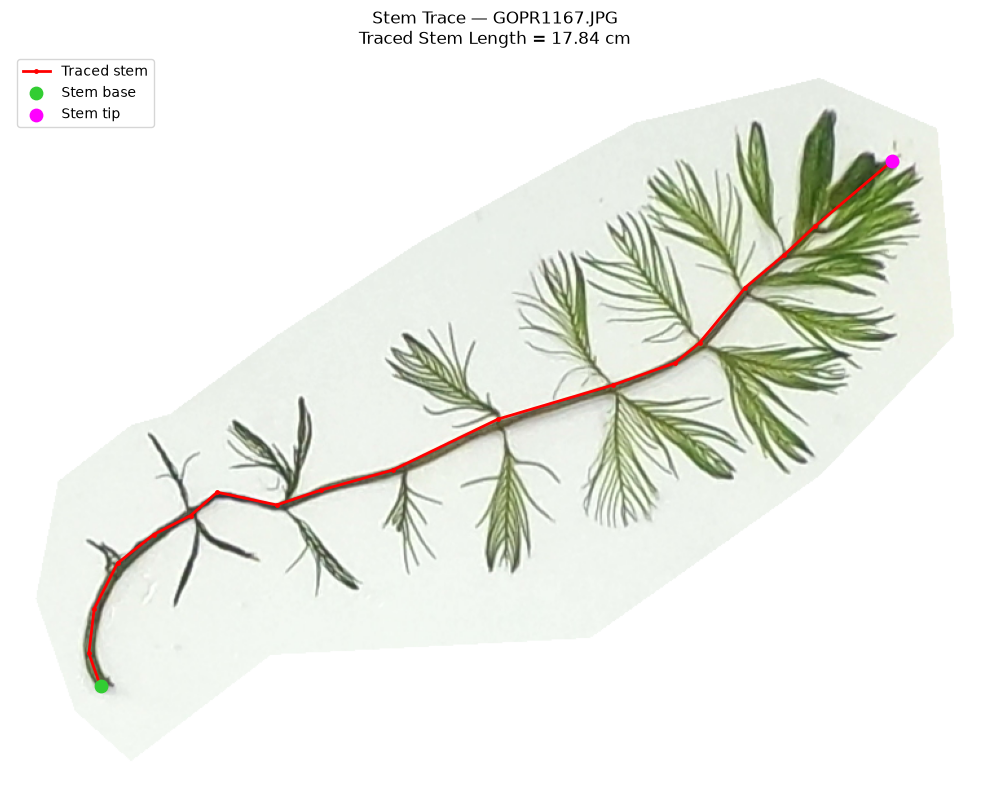

Number of traced points: 18
Pixel size: 0.022285 cm/pixel
Traced stem length: 17.84 cm


In [10]:

# ==================================================
# INTERACTIVE STEM TRACING
# ==================================================

%matplotlib tk

# --------------------------------------------------
# STEP 1: Display photograph for stem tracing
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(cropped_rgb)

ax.set_xlim(xmin - 20, xmax + 20)
ax.set_ylim(ymax + 20, ymin - 20)

ax.set_title(
    f"IDX {selected_idx} — Branch {selected_branch}\n"
    "Trace the main stem from BASE to TIP\n"
    "Press ENTER when finished"
)

# --------------------------------------------------
# STEP 2: Record stem coordinates
# --------------------------------------------------

stem_points = np.array(plt.ginput(n=-1, timeout=0))

plt.close(fig)

if len(stem_points) < 2:
    raise ValueError("At least two points are required to trace the stem.")

# --------------------------------------------------
# STEP 3: Retrieve pixel-size calibration
# --------------------------------------------------

pixel_size_cm = float(
    metadata_row["MeanPixelSize_cmPerPixel"].iloc[0]
)

# --------------------------------------------------
# STEP 4: Calculate cumulative axial distance
# --------------------------------------------------

segment_lengths_px = np.linalg.norm(
    np.diff(stem_points, axis=0),
    axis=1
)

cumulative_distance_px = np.concatenate([
    [0],
    np.cumsum(segment_lengths_px)
])

cumulative_distance_cm = (
    cumulative_distance_px * pixel_size_cm
)

stem_length_cm = cumulative_distance_cm[-1]

# --------------------------------------------------
# STEP 5: Visualize traced stem
# --------------------------------------------------

%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(cropped_rgb)

ax.plot(
    stem_points[:, 0],
    stem_points[:, 1],
    "r.-",
    linewidth=2,
    markersize=5,
    label="Traced stem"
)

ax.scatter(
    *stem_points[0],
    color="limegreen",
    s=80,
    label="Stem base",
    zorder=5
)

ax.scatter(
    *stem_points[-1],
    color="magenta",
    s=80,
    label="Stem tip",
    zorder=5
)

ax.set_xlim(xmin - 20, xmax + 20)
ax.set_ylim(ymax + 20, ymin - 20)

ax.set_title(
    f"Stem Trace — {branch_filename}\n"
    f"Traced Stem Length = {stem_length_cm:.2f} cm"
)

ax.legend(loc="upper left")
ax.axis("off")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# STEP 6: Report stem measurements
# --------------------------------------------------

print(f"Number of traced points: {len(stem_points)}")
print(f"Pixel size: {pixel_size_cm:.6f} cm/pixel")
print(f"Traced stem length: {stem_length_cm:.2f} cm")


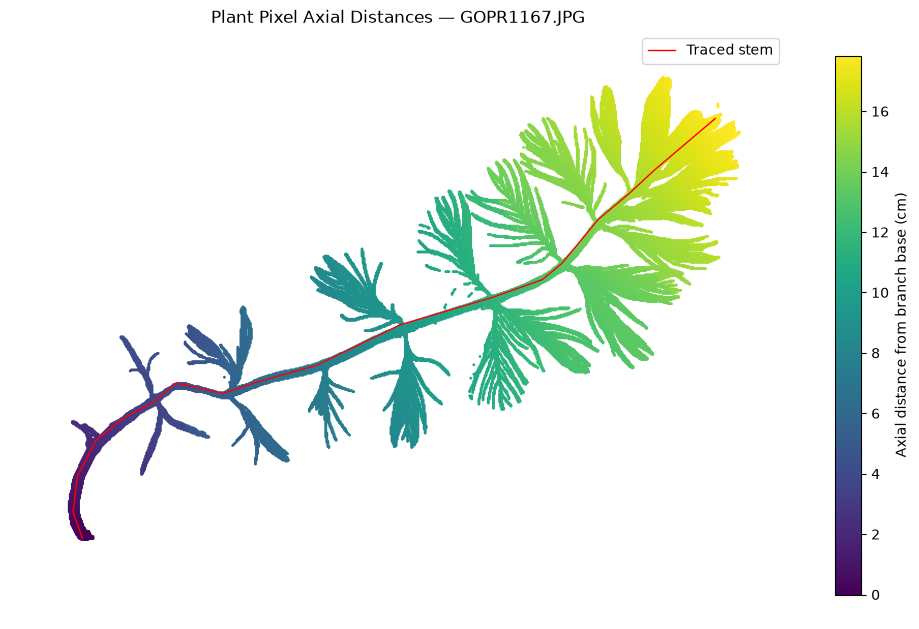

Total plant pixels: 37,568
Assigned plant pixels: 37,568
Minimum axial distance: 0.00 cm
Maximum axial distance: 17.84 cm


In [11]:

# ==================================================
# PROJECT PLANT PIXELS ONTO THE TRACED STEM
# ==================================================

# --------------------------------------------------
# STEP 1: Extract coordinates of classified plant pixels
# --------------------------------------------------

plant_y, plant_x = np.where(plant_mask)

plant_coordinates = np.column_stack([
    plant_x,
    plant_y
]).astype(float)


# --------------------------------------------------
# STEP 2: Initialize arrays for pixel projections
# --------------------------------------------------

minimum_distance_sq = np.full(
    len(plant_coordinates),
    np.inf
)

pixel_axial_distance_px = np.zeros(
    len(plant_coordinates)
)


# --------------------------------------------------
# STEP 3: Project plant pixels onto stem segments
# --------------------------------------------------

for i in range(len(stem_points) - 1):

    segment_start = stem_points[i]
    segment_end = stem_points[i + 1]

    segment_vector = segment_end - segment_start

    segment_length_sq = np.dot(
        segment_vector,
        segment_vector
    )

    if segment_length_sq == 0:
        continue

    # Calculate projection onto the current segment
    t = (
        (plant_coordinates - segment_start)
        @ segment_vector
    ) / segment_length_sq

    # Restrict projections to the segment boundaries
    t = np.clip(t, 0, 1)

    projected_coordinates = (
        segment_start + t[:, None] * segment_vector
    )

    # Calculate distance between pixels and projections
    distance_sq = np.sum(
        (plant_coordinates - projected_coordinates)**2,
        axis=1
    )

    # Retain the closest projection for each pixel
    closer = distance_sq < minimum_distance_sq

    minimum_distance_sq[closer] = distance_sq[closer]

    pixel_axial_distance_px[closer] = (
        cumulative_distance_px[i]
        + t[closer] * segment_lengths_px[i]
    )


# --------------------------------------------------
# STEP 4: Convert axial distances to centimeters
# --------------------------------------------------

pixel_axial_distance_cm = (
    pixel_axial_distance_px * pixel_size_cm
)


# --------------------------------------------------
# STEP 5: Visualize axial distance assignments
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

sc = ax.scatter(
    plant_x,
    plant_y,
    c=pixel_axial_distance_cm,
    cmap="viridis",
    s=1
)

ax.plot(
    stem_points[:, 0],
    stem_points[:, 1],
    color="red",
    linewidth=1,
    label="Traced stem"
)

ax.set_xlim(xmin - 20, xmax + 20)
ax.set_ylim(ymax + 20, ymin - 20)

ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    f"Plant Pixel Axial Distances — {branch_filename}"
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("Axial distance from branch base (cm)")

ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# STEP 6: Verify pixel assignments
# --------------------------------------------------

print(f"Total plant pixels: {plant_pixel_count:,}")
print(f"Assigned plant pixels: {len(pixel_axial_distance_cm):,}")
print(f"Minimum axial distance: {pixel_axial_distance_cm.min():.2f} cm")
print(f"Maximum axial distance: {pixel_axial_distance_cm.max():.2f} cm")


,IDX,BRANCHNUM,Interval_Start_cm,Interval_End_cm,Interval_Center_cm,Plant_Pixel_Count,Projected_Area_cm2
0,3,2,0.0,1.0,0.5,489,0.242977
1,3,2,1.0,2.0,1.5,417,0.207201
2,3,2,2.0,3.0,2.5,656,0.325957
3,3,2,3.0,4.0,3.5,827,0.410924
4,3,2,4.0,5.0,4.5,853,0.423844
5,3,2,5.0,6.0,5.5,1302,0.646945
6,3,2,6.0,7.0,6.5,960,0.477010
7,3,2,7.0,8.0,7.5,956,0.475023
8,3,2,8.0,9.0,8.5,2403,1.194016
9,3,2,9.0,10.0,9.5,2126,1.056379


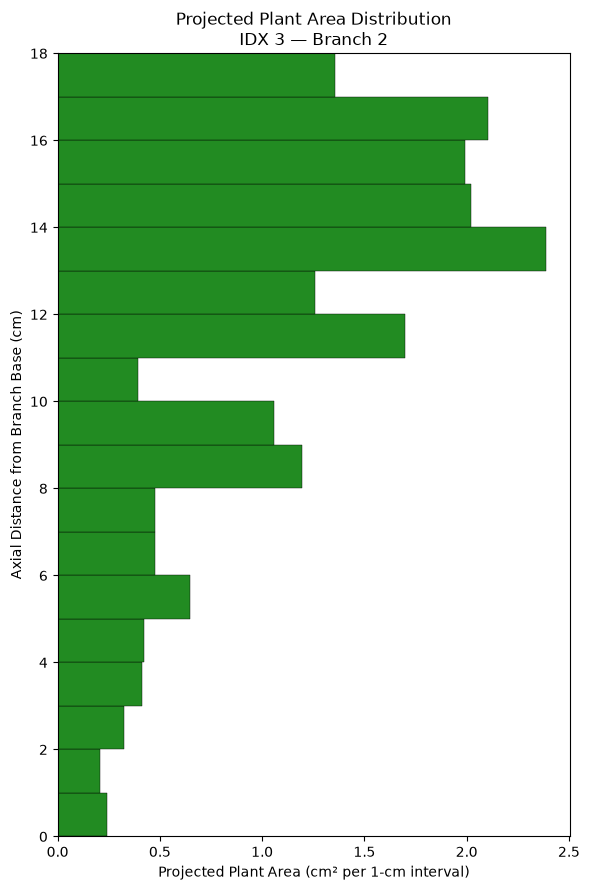

Number of intervals: 18
Total classified plant area: 18.67 cm²
Total distributed plant area: 18.67 cm²
Difference: 0.000000 cm²
Area conservation check: True


In [13]:

# ==================================================
# PROJECTED PLANT AREA IN 1-CM AXIAL INTERVALS
# ==================================================

# --------------------------------------------------
# STEP 1: Define 1-cm axial intervals
# --------------------------------------------------

bin_width_cm = 1

bin_edges_cm = np.arange(
    0,
    np.ceil(stem_length_cm) + bin_width_cm,
    bin_width_cm
)

bin_centers_cm = (
    bin_edges_cm[:-1] + bin_edges_cm[1:]
) / 2


# --------------------------------------------------
# STEP 2: Count plant pixels within each interval
# --------------------------------------------------

pixel_counts, _ = np.histogram(
    pixel_axial_distance_cm,
    bins=bin_edges_cm
)


# --------------------------------------------------
# STEP 3: Convert pixel counts to projected area
# --------------------------------------------------

interval_area_cm2 = pixel_counts * pixel_area_cm2


# --------------------------------------------------
# STEP 4: Create branch area distribution table
# --------------------------------------------------

branch_distribution = pd.DataFrame({
    "IDX": selected_idx,
    "BRANCHNUM": selected_branch,
    "Interval_Start_cm": bin_edges_cm[:-1],
    "Interval_End_cm": bin_edges_cm[1:],
    "Interval_Center_cm": bin_centers_cm,
    "Plant_Pixel_Count": pixel_counts,
    "Projected_Area_cm2": interval_area_cm2
})

display(branch_distribution.head(10))


# --------------------------------------------------
# STEP 5: Plot projected plant area distribution
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 9))

ax.barh(
    bin_centers_cm,
    interval_area_cm2,
    height=bin_width_cm,
    color="forestgreen",
    edgecolor="black",
    linewidth=0.3
)

ax.set_xlabel("Projected Plant Area (cm² per 1-cm interval)")
ax.set_ylabel("Axial Distance from Branch Base (cm)")

ax.set_title(
    f"Projected Plant Area Distribution\n"
    f"IDX {selected_idx} — Branch {selected_branch}"
)

ax.set_ylim(0, bin_edges_cm[-1])
ax.set_xlim(left=0)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# STEP 6: Verify conservation of projected plant area
# --------------------------------------------------

distributed_area_cm2 = interval_area_cm2.sum()

print(f"Number of intervals: {len(interval_area_cm2)}")
print(f"Total classified plant area: {total_plant_area_cm2:.2f} cm²")
print(f"Total distributed plant area: {distributed_area_cm2:.2f} cm²")
print(f"Difference: {total_plant_area_cm2 - distributed_area_cm2:.6f} cm²")

print(
    "Area conservation check:",
    np.isclose(distributed_area_cm2, total_plant_area_cm2)
)


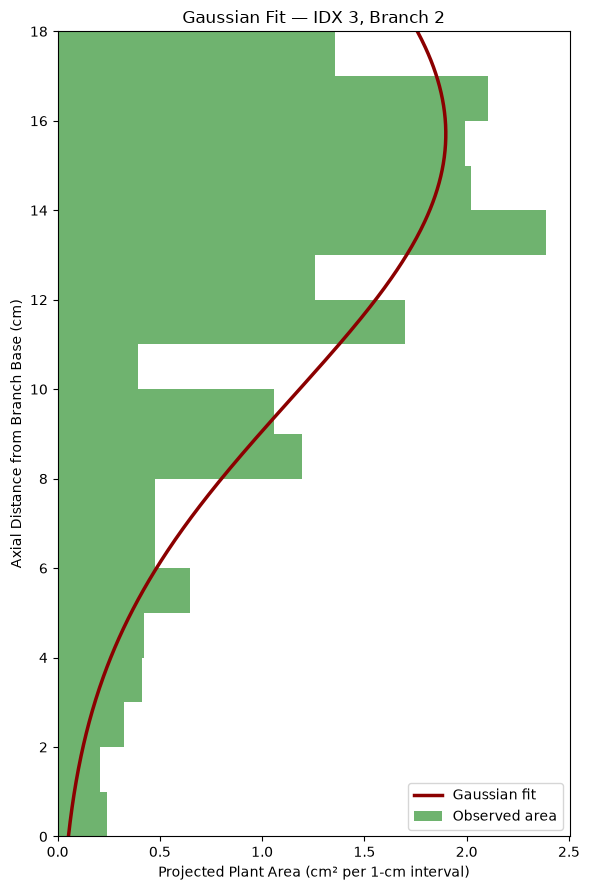

Amplitude: 1.898 cm² per interval
Peak axial distance (μ): 15.71 cm
Spread (σ): 5.87 cm
R²: 0.785


In [14]:

# ==================================================
# GAUSSIAN FIT TO PROJECTED PLANT AREA DISTRIBUTION
# ==================================================

from scipy.optimize import curve_fit

# STEP 1: Define Gaussian function
def gaussian(z, amplitude, mean, sigma):
    return amplitude * np.exp(
        -0.5 * ((z - mean) / sigma)**2
    )

# STEP 2: Prepare observations
z = bin_centers_cm
area = interval_area_cm2

# STEP 3: Fit Gaussian model
initial_guess = [
    area.max(),
    z[np.argmax(area)],
    5.0
]

parameters, covariance = curve_fit(
    gaussian,
    z,
    area,
    p0=initial_guess,
    bounds=([0, 0, 0.01], [np.inf, np.inf, np.inf]),
    maxfev=10000
)

amplitude, mean, sigma = parameters

# STEP 4: Calculate fitted values and R²
area_predicted = gaussian(z, *parameters)

ss_res = np.sum((area - area_predicted)**2)
ss_tot = np.sum((area - area.mean())**2)

r_squared = 1 - ss_res / ss_tot

# STEP 5: Plot observed distribution and Gaussian fit
z_smooth = np.linspace(0, bin_edges_cm[-1], 500)
area_smooth = gaussian(z_smooth, *parameters)

fig, ax = plt.subplots(figsize=(6, 9))

ax.barh(
    z,
    area,
    height=bin_width_cm,
    color="forestgreen",
    alpha=0.65,
    label="Observed area"
)

ax.plot(
    area_smooth,
    z_smooth,
    color="darkred",
    linewidth=2.5,
    label="Gaussian fit"
)

ax.set_xlabel("Projected Plant Area (cm² per 1-cm interval)")
ax.set_ylabel("Axial Distance from Branch Base (cm)")

ax.set_title(
    f"Gaussian Fit — IDX {selected_idx}, Branch {selected_branch}"
)

ax.set_ylim(0, bin_edges_cm[-1])
ax.set_xlim(left=0)

ax.legend()

plt.tight_layout()
plt.show()

# STEP 6: Report fitted parameters
print(f"Amplitude: {amplitude:.3f} cm² per interval")
print(f"Peak axial distance (μ): {mean:.2f} cm")
print(f"Spread (σ): {sigma:.2f} cm")
print(f"R²: {r_squared:.3f}")


In [15]:

# ==================================================
# EXAMINE GAUSSIAN FIT PARAMETERS
# ==================================================

from scipy.stats import t

# STEP 1: Calculate parameter standard errors
parameter_se = np.sqrt(np.diag(covariance))

# STEP 2: Calculate approximate 95% confidence intervals
degrees_freedom = len(area) - len(parameters)

t_critical = t.ppf(0.975, degrees_freedom)

ci_lower = parameters - t_critical * parameter_se
ci_upper = parameters + t_critical * parameter_se

# STEP 3: Calculate RMSE
rmse = np.sqrt(np.mean((area - area_predicted)**2))

# STEP 4: Summarize fitted parameters
fit_summary = pd.DataFrame({
    "Parameter": ["Amplitude (A₀)", "Peak position (μ)", "Spread (σ)"],
    "Estimate": parameters,
    "Standard Error": parameter_se,
    "95% CI Lower": ci_lower,
    "95% CI Upper": ci_upper
})

display(fit_summary.round(3))

print(f"R²: {r_squared:.3f}")
print(f"RMSE: {rmse:.3f} cm² per interval")
print(f"Degrees of freedom: {degrees_freedom}")


,Parameter,Estimate,Standard Error,95% CI Lower,95% CI Upper
0,Amplitude (A₀),1.898,0.163,1.552,2.245
1,Peak position (μ),15.708,1.613,12.270,19.147
2,Spread (σ),5.870,1.290,3.121,8.618


R²: 0.785
RMSE: 0.333 cm² per interval
Degrees of freedom: 15


### Interpretation of the Gaussian Fit

The projected plant area distribution for Branch 2 of IDX 3
exhibits a nonuniform distribution of plant tissue, with
relatively little projected area near the branch base and
greater projected area toward the tip.

The Gaussian model explained approximately 78.5% of the
observed variation in projected plant area among the 1-cm
axial intervals (R² = 0.785), with a root mean square error
(RMSE) of 0.333 cm² per interval.

These results suggest that a Gaussian function provides a
reasonable first-order approximation of the projected plant
area distribution for this branch.

However, the Gaussian function assumes symmetry around its
peak, whereas branching plant architecture may produce
asymmetric or multimodal distributions.

Further analysis across branches and individual shoots is
necessary to determine whether a Gaussian function is
appropriate for characterizing projected plant area
distributions in Myriophyllum.

### The Results from the Rest of the Branches

You will also need to download the vertical_area folder within the DATA>results subfolder in order to load the vertical distributions of all the branches

In [ ]:

# ==================================================
# LOAD PREVIOUSLY PROCESSED BRANCH DISTRIBUTIONS
# ==================================================

# --------------------------------------------------
# STEP 1: Define folder path
# --------------------------------------------------

# Message to Lu: Replace this path with the location
# of the vertical_area folder on your computer.

vertical_area_folder = Path(
    r"C:\Users\mguar\Documents\OEAS805\FinalProject\DATA\results\vertical_area"
)


# --------------------------------------------------
# STEP 2: Identify branch distribution files
# --------------------------------------------------

branch_files = [
    "GOPR1166_verticalarea.csv",
    "GOPR1167_verticalarea.csv",
    "GOPR1173_verticalarea.csv",
    "GOPR1175_verticalarea.csv",
    "GOPR1177_verticalarea.csv"
]


# --------------------------------------------------
# STEP 3: Load and combine branch distributions
# --------------------------------------------------

branch_tables = []

for filename in branch_files:

    file_path = vertical_area_folder / filename

    branch_table = pd.read_csv(file_path)

    branch_tables.append(branch_table)

    print(f"Loaded: {filename}")

all_branch_distributions = pd.concat(
    branch_tables,
    ignore_index=True
)


# --------------------------------------------------
# STEP 4: Verify loaded data
# --------------------------------------------------

print("\nShoot IDs:",
      all_branch_distributions["IDX"].unique())

print("Branch numbers:",
      sorted(all_branch_distributions["BRANCHNUM"].unique()))

print("Total number of records:",
      len(all_branch_distributions))


# --------------------------------------------------
# STEP 5: Summarize projected plant area by branch
# --------------------------------------------------

branch_area_summary = (
    all_branch_distributions
    .groupby(["IDX", "BRANCHNUM", "BRANCH"])
    ["AREA_CM2"]
    .sum()
    .reset_index()
)

branch_area_summary = branch_area_summary.rename(
    columns={"AREA_CM2": "Total_Projected_Area_cm2"}
)

# Calculate total shoot area
total_shoot_area_cm2 = (
    branch_area_summary["Total_Projected_Area_cm2"].sum()
)

# Calculate percentage contribution of each branch
branch_area_summary["Percent_of_Shoot_Area"] = (
    branch_area_summary["Total_Projected_Area_cm2"]
    / total_shoot_area_cm2 * 100
)

display(branch_area_summary.round(2))

print(
    f"\nTotal projected shoot area: "
    f"{total_shoot_area_cm2:.2f} cm²"
)


Loaded: GOPR1166_verticalarea.csv
Loaded: GOPR1167_verticalarea.csv
Loaded: GOPR1173_verticalarea.csv
Loaded: GOPR1175_verticalarea.csv
Loaded: GOPR1177_verticalarea.csv

Shoot IDs: [3]
Branch numbers: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Total number of records: 429


,IDX,BRANCHNUM,BRANCH,Total_Projected_Area_cm2,Percent_of_Shoot_Area
0,3,1,GOPR1166,42.23,10.33
1,3,2,GOPR1167,20.27,4.96
2,3,3,GOPR1173,160.62,39.31
3,3,4,GOPR1175,162.13,39.68
4,3,5,GOPR1177,23.40,5.73



Total projected shoot area: 408.65 cm²


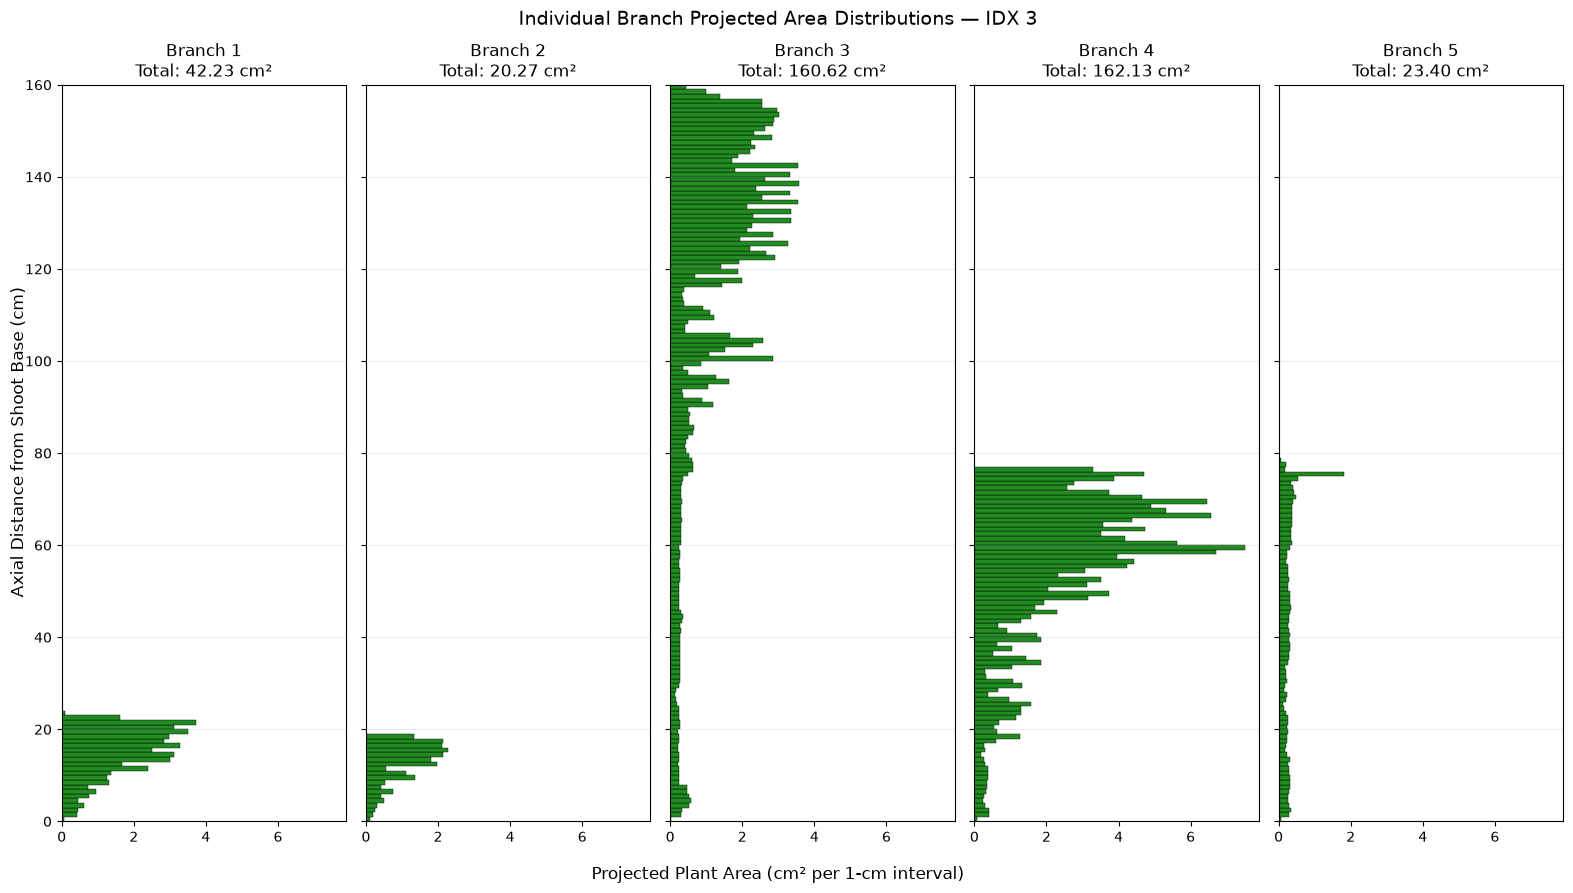

In [18]:

# ==================================================
# COMPARE INDIVIDUAL BRANCH AREA DISTRIBUTIONS
# ==================================================

# STEP 1: Sum area across plant parts within each branch
individual_branch_profiles = (
    all_branch_distributions
    .groupby([
        "BRANCHNUM",
        "HEIGHT_LOWER_CM",
        "HEIGHT_UPPER_CM"
    ])["AREA_CM2"]
    .sum()
    .reset_index()
)

# STEP 2: Calculate interval centers
individual_branch_profiles["Interval_Center_cm"] = (
    individual_branch_profiles["HEIGHT_LOWER_CM"]
    + individual_branch_profiles["HEIGHT_UPPER_CM"]
) / 2

# STEP 3: Determine common axis limits
max_area = individual_branch_profiles["AREA_CM2"].max()

max_distance = individual_branch_profiles[
    "HEIGHT_UPPER_CM"
].max()

branch_numbers = sorted(
    individual_branch_profiles["BRANCHNUM"].unique()
)

# STEP 4: Create individual branch subplots
fig, axes = plt.subplots(
    1, 5,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

for ax, branch_num in zip(axes, branch_numbers):

    profile = individual_branch_profiles.loc[
        individual_branch_profiles["BRANCHNUM"] == branch_num
    ]

    branch_total_area = profile["AREA_CM2"].sum()

    ax.barh(
        profile["Interval_Center_cm"],
        profile["AREA_CM2"],
        height=1,
        color="forestgreen",
        edgecolor="black",
        linewidth=0.3
    )

    ax.set_title(
        f"Branch {branch_num}\n"
        f"Total: {branch_total_area:.2f} cm²"
    )

    ax.set_xlim(0, max_area * 1.05)
    ax.set_ylim(0, max_distance)

    ax.grid(axis="y", alpha=0.2)

# STEP 5: Add shared figure labels
fig.supxlabel(
    "Projected Plant Area (cm² per 1-cm interval)"
)

fig.supylabel(
    "Axial Distance from Shoot Base (cm)"
)

fig.suptitle(
    "Individual Branch Projected Area Distributions — IDX 3",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Interpretation of Individual Branch Area Distributions

The five branches of IDX 3 exhibit substantial differences in
axial length, total projected plant area, and the distribution
of plant tissue along their axes.

Branches 1 and 2 are relatively short, with projected plant
area concentrated toward their distal ends. Branch 3 extends
approximately 160 cm, with relatively little projected area
along its lower portion and greater area toward its distal end.

Branch 4 contains the greatest total projected plant area
(162.13 cm²), despite extending approximately half the axial
distance of Branch 3 (160.62 cm²). Together, Branches 3 and 4
account for approximately 79% of the total projected shoot area.

A particularly interesting finding is that axial length alone
is not a reliable indicator of projected plant area within
this shoot. For example, Branches 4 and 5 have similar axial
lengths, yet Branch 4 contains nearly seven times as much
projected plant area as Branch 5.

These observations highlight why characterizing plant
architecture requires more than measuring plant length or
total projected area alone. Quantifying the spatial
distribution of plant tissue provides additional information
about plant architecture that cannot be captured by either
of these measurements independently.

The differences among individual branch distributions also
suggest that the reconstructed whole-shoot distribution may
exhibit multiple peaks associated with the contributions of
different branches.